./datasets\test
test 3
./datasets\train
train 3
Collected 147 file paths.
Collected 147 labels.
First 5 file paths: ['./datasets\\test\\messi\\2026-07-07T182712Z_975197803_UP1EM771F9B49_RTRMADP_3_SOCCER-WORLDCUP-ARG-EGY-e1783462409146.jpg', './datasets\\test\\messi\\70a8aeb0-d105-11f0-a4c7-5dbeb8de769b.jpg', './datasets\\test\\messi\\dec890b0-79ae-11ed-bf69-f4bc15d1bbaf.webp', './datasets\\test\\messi\\images (1).jpg', './datasets\\test\\messi\\images (2).jpg']
First 5 labels: [0, 0, 0, 0, 0]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0151556..2.3785625].


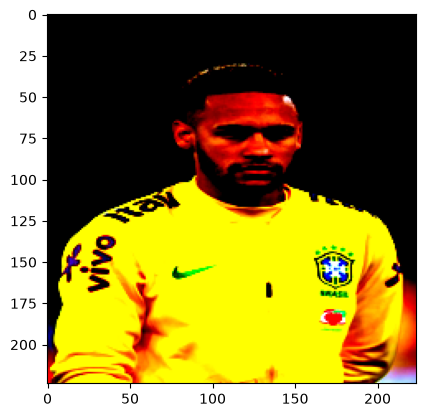

Label: tensor([2, 0, 0, 1, 1, 1, 2, 1])
0.5333333333333333
The model predicts this image is of: ronaldo


In [1]:
import os
import zipfile
# root = "./datasets.zip"

# with zipfile.ZipFile('./datasets.zip', 'r') as zip_ref:
#     zip_ref.extractall('./')

root = './datasets'

for folder in os.listdir(root):
    path = os.path.join(root, folder)
    print(path)
    print(folder, len(os.listdir(path)))

file_paths = []
labels = []

label_map = {"messi": 0, "ronaldo": 1, "neymar": 2}

# Iterate through the main data folders (e.g., 'test', 'train')
for root_folder_name in sorted(os.listdir(root)):
    root_folder_path = os.path.join(root, root_folder_name)

    # Check if it's a directory (to avoid files like .DS_Store if they exist)
    if os.path.isdir(root_folder_path):
        # Iterate through the category folders (e.g., 'messi', 'ronaldo') inside 'test' or 'train'
        for category_folder_name in sorted(os.listdir(root_folder_path)):
            category_folder_path = os.path.join(root_folder_path, category_folder_name)

            # Check if it's a directory and if its name is in our label_map
            if os.path.isdir(category_folder_path) and category_folder_name in label_map:
                for file_name in sorted(os.listdir(category_folder_path)):
                    file_full_path = os.path.join(category_folder_path, file_name)
                    file_paths.append(file_full_path)
                    labels.append(label_map[category_folder_name])

print(f"Collected {len(file_paths)} file paths.")
print(f"Collected {len(labels)} labels.")
# Display the first few collected file paths and labels for verification
print("First 5 file paths:", file_paths[:5])
print("First 5 labels:", labels[:5])

from sklearn.model_selection import train_test_split

train_paths, test_paths, train_labels, test_labels = train_test_split(
    file_paths,
    labels,
    test_size=0.2,
    random_state=42,
)

# Image Classification
import torch
from torchvision.transforms import v2

transforms = v2.Compose([
    v2.ToImage(),
    v2.Resize(size=(224, 224), antialias=True),
    v2.ToDtype(torch.float32, scale=True),  # Convert images to float32 and scale to [0.0, 1.0]
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normalize with ImageNet stats
])

from torch.utils.data import Dataset, DataLoader
from PIL import Image

class ImageData(Dataset):
    def __init__(self, file_paths, labels, transforms=None):
        self.file_paths = file_paths
        self.labels = labels
        self.transforms = transforms

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, index):
        image = Image.open(self.file_paths[index]).convert('RGB')
        label = self.labels[index]

        if self.transforms:
            image = self.transforms(image)
        return image, label

train_dataset = ImageData(train_paths, train_labels, transforms)
test_dataset = ImageData(test_paths, test_labels, transforms)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=8)

import matplotlib.pyplot as plt
train_features, train_labels = next(iter(train_loader))
image = train_features[0].squeeze()
label = train_labels
plt.imshow(image.permute(1, 2, 0))
plt.show()
print(f"Label: {label}")

from torch import nn

class ImageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.sequential = nn.Sequential(
            nn.Conv2d(3, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(64, 3),
        )

    def forward(self, x):
        return self.sequential(x)

model = ImageModel()
criterion = nn.CrossEntropyLoss()
optimize = torch.optim.Adam(model.parameters(), lr=0.001)

import random
import numpy as np
import torch

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


for epoch in range(50):
    model.train()

    for x, y in train_loader:
        predictions = model(x)
        loss = criterion(predictions, y)
        optimize.zero_grad()
        loss.backward()
        optimize.step()
torch.save(model.state_dict(), 'model_state.pth')


model = ImageModel()
model.load_state_dict(torch.load('model_state.pth'))
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for x, y in test_loader:
        predictions = model(x)
        predicted = predictions.argmax(1)
        correct += (predicted == y).sum().item()
        total += y.size(0)

accuracy = correct / total
print(accuracy)

import torchvision.transforms.functional as TF
from PIL import Image as PILImage

# Path to your new image for testing
new_image_path = './images.jpg'  # Example path, replace with your image

# Load the image
try:
    new_image = PILImage.open(new_image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: Image file not found at {new_image_path}")
    new_image = None

if new_image:
    transformed_image = transforms(new_image)
    input_tensor = transformed_image.unsqueeze(0)
    model.eval()

    with torch.no_grad():
        output = model(input_tensor)

    _, predicted_class_idx = torch.max(output, 1)
    reverse_label_map = {v: k for k, v in label_map.items()}
    predicted_label = reverse_label_map[predicted_class_idx.item()]
    print(f"The model predicts this image is of: {predicted_label}")
else:
    print("Could not process the image.")




In [2]:
for name in label_map:
    count = len(os.listdir(f"./datasets/train/{name}"))
    print(name, count)

for name in label_map:
    count = len(os.listdir(f"./datasets/test/{name}"))
    print(name, count)

messi 30
ronaldo 43
neymar 34
messi 14
ronaldo 13
neymar 13


In [3]:
# import os

# folders = [
#     "dataset/train/messi",
#     "dataset/train/ronaldo",
#     "dataset/train/neymar",
# ]

# for folder in folders:
#     os.makedirs(folder, exist_ok=True)

# from icrawler.builtin import BingImageCrawler

# players = {
#     "messi": "Lionel Messi",
#     "ronaldo": "Cristiano Ronaldo",
#     "neymar": "Neymar Jr"
# }

# for folder, keyword in players.items():
#     crawler = BingImageCrawler(
#         storage={"root_dir": f"dataset/train/{folder}"}
#     )

#     crawler.crawl(
#         keyword=keyword,
#         max_num=150
#     )

# print("Finished downloading!")

In [ ]:
# import os
# import random
# import shutil

# random.seed(42)

# players = ["messi", "ronaldo", "neymar"]

# for player in players:
#     train_folder = f"dataset/train/{player}"
#     test_folder = f"dataset/test/{player}"

#     os.makedirs(test_folder, exist_ok=True)

#     images = os.listdir(train_folder)
#     random.shuffle(images)

#     # Move 30 images to test
#     for image in images[:30]:
#         shutil.move(
#             os.path.join(train_folder, image),
#             os.path.join(test_folder, image)
#         )

# print("Dataset split complete!")

In [4]:

import torchvision.transforms.functional as TF
from PIL import Image as PILImage

# Path to your new image for testing
new_image_path = './images.jpg'  # Example path, replace with your image

# Load the image
try:
    new_image = PILImage.open(new_image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: Image file not found at {new_image_path}")
    new_image = None

if new_image:
    transformed_image = transforms(new_image)
    input_tensor = transformed_image.unsqueeze(0)
    model.eval()

    with torch.no_grad():
        output = model(input_tensor)

    _, predicted_class_idx = torch.max(output, 1)
    reverse_label_map = {v: k for k, v in label_map.items()}
    predicted_label = reverse_label_map[predicted_class_idx.item()]
    print(f"The model predicts this image is of: {predicted_label}")
else:
    print("Could not process the image.")


The model predicts this image is of: ronaldo


In [5]:
# ml/model_loader.py

import torch
model = ImageModel()

model.load_state_dict(
    torch.load("model_state.pth", map_location="cpu")
)

model.eval()

with torch.no_grad():
    new_image_path = './images.jpg'  # Example path, replace with your image

# Load the image
    try:
        new_image = PILImage.open(new_image_path).convert('RGB')
    except FileNotFoundError:
        print(f"Error: Image file not found at {new_image_path}")
        new_image = None

    if new_image:
        transformed_image = transforms(new_image)
        input_tensor = transformed_image.unsqueeze(0)

        output = model(input_tensor)

        _, predicted_class_idx = torch.max(output, 1)
        reverse_label_map = {v: k for k, v in label_map.items()}
        predicted_label = reverse_label_map[predicted_class_idx.item()]
        print(f"The model predicts this image is of: {predicted_label}")


    # return result

The model predicts this image is of: ronaldo
